# Approach A: Total Calories Burned
**Question:** what drives the *total* calories a member burns in one session, and can we sort sessions into Low / Mid / High?

Sections:
1. Men vs women: why are calories so close?
2. The 1,500+ calorie sessions (outliers)
3. How much do the main factors affect calories?
4. Experience → Duration → Fat % → Calories?
5. Low / Mid / High bins (3 methods)
6. Does keeping or dropping the 1,500+ sessions change a model?

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import cross_val_score

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)

df = pd.read_csv("https://raw.githubusercontent.com/salioudunn11/Fitness_Prediction/main/gym_members_exercise_tracking.csv")
df = df.rename(columns={
    "Weight (kg)": "Weight", "Height (m)": "Height",
    "Session_Duration (hours)": "Duration",
    "Water_Intake (liters)": "Water_Intake",
    "Workout_Frequency (days/week)": "Frequency",
})
print(df.shape)

(973, 15)


## 1. Men vs Women
Men weigh much more on average, so in real life they should burn noticeably more. Let's check.

In [2]:
display(df.groupby("Gender")[["Calories_Burned", "Weight", "Duration", "Avg_BPM", "Fat_Percentage"]].mean().round(1))

,Calories_Burned,Weight,Duration,Avg_BPM,Fat_Percentage
Gender,,,,,
Female,862.2,60.9,1.3,143.6,27.7
Male,944.5,85.5,1.3,143.9,22.6


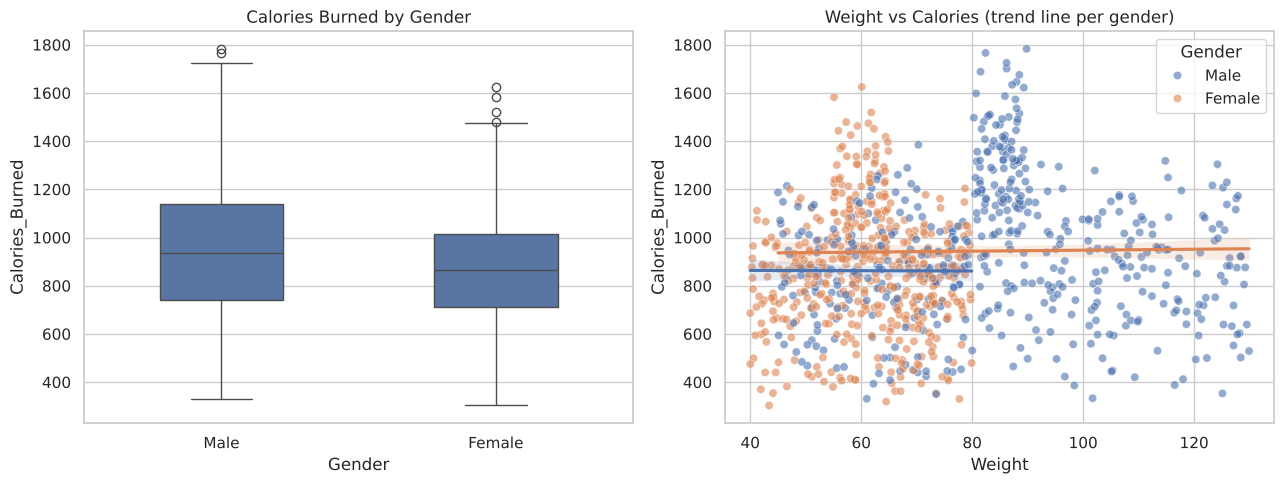

Female: correlation of Weight with Calories = -0.00
Male: correlation of Weight with Calories = 0.02


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=df, x="Gender", y="Calories_Burned", ax=axes[0], width=0.45)
axes[0].set_title("Calories Burned by Gender")

sns.scatterplot(data=df, x="Weight", y="Calories_Burned", hue="Gender", alpha=0.6, ax=axes[1])
for g, d in df.groupby("Gender"):
    sns.regplot(data=d, x="Weight", y="Calories_Burned", scatter=False, ax=axes[1])
axes[1].set_title("Weight vs Calories (trend line per gender)")
plt.tight_layout(); plt.show()

for g, d in df.groupby("Gender"):
    print(f"{g}: correlation of Weight with Calories = {d['Weight'].corr(d['Calories_Burned']):.2f}")

**What to notice:** the trend lines are flat. Inside each gender, a heavier person does **not** burn more calories. Real bodies don't work that way: heavier people burn more for the same effort.

Next: if weight doesn't explain calories, what does? Fit calories using only Duration × Avg heart rate (plus age), separately for each gender:

In [4]:
for g, d in df.groupby("Gender"):
    X = pd.DataFrame({
        "dur_x_bpm": d["Duration"] * d["Avg_BPM"],
        "dur_x_bpm_x_age": d["Duration"] * d["Avg_BPM"] * d["Age"],
        "dur": d["Duration"],
    })
    r2 = LinearRegression().fit(X, d["Calories_Burned"]).score(X, d["Calories_Burned"])
    print(f"{g}: R² using only duration, heart rate and age = {r2:.3f}")

Female: R² using only duration, heart rate and age = 0.991
Male: R² using only duration, heart rate and age = 0.991


**Takeaway:** about 99% of calories are explained by duration, heart rate and age, using a different formula for each gender. Real measured or self-reported data is never this clean. The calories look **calculated from a heart-rate formula**, not measured or reported by members.

## 2. The 1,500+ Calorie Sessions

In [5]:
c = df["Calories_Burned"]
q1, q3 = c.quantile([0.25, 0.75])
iqr_fence = q3 + 1.5 * (q3 - q1)
z3_fence = c.mean() + 3 * c.std()

print(f"Sessions over 1,500 kcal:          {(c > 1500).sum()}")
print(f"Boxplot (IQR) fence:  {iqr_fence:.0f} kcal -> {(c > iqr_fence).sum()} sessions above")
print(f"Z-score > 3 fence:    {z3_fence:.0f} kcal -> {(c > z3_fence).sum()} sessions above")

Sessions over 1,500 kcal:          20
Boxplot (IQR) fence:  1610 kcal -> 10 sessions above
Z-score > 3 fence:    1723 kcal -> 3 sessions above


In [6]:
high = df[df["Calories_Burned"] > 1500].copy()
high["Cal_per_Hour"] = (high["Calories_Burned"] / high["Duration"]).round(0)
display(high[["Gender", "Age", "Weight", "Experience_Level", "Workout_Type",
              "Duration", "Avg_BPM", "Calories_Burned", "Cal_per_Hour"]]
        .sort_values("Calories_Burned", ascending=False))

,Gender,Age,Weight,Experience_Level,Workout_Type,Duration,Avg_BPM,Calories_Burned,Cal_per_Hour
910,Male,32,89.8,3,Strength,1.93,168,1783.0,924.0
712,Male,19,82.4,3,HIIT,1.90,169,1766.0,929.0
511,Male,39,86.2,3,Strength,1.96,160,1725.0,880.0
124,Male,26,86.2,3,Strength,1.97,157,1701.0,863.0
90,Male,25,81.5,3,HIIT,1.93,159,1688.0,875.0
646,Male,22,88.5,3,Strength,1.88,162,1675.0,891.0
572,Male,36,88.0,3,HIIT,1.87,160,1646.0,880.0
728,Male,47,87.2,3,Strength,2.00,165,1634.0,817.0
99,Female,24,60.1,3,Cardio,1.97,165,1625.0,825.0
475,Male,27,89.3,3,HIIT,1.82,162,1622.0,891.0


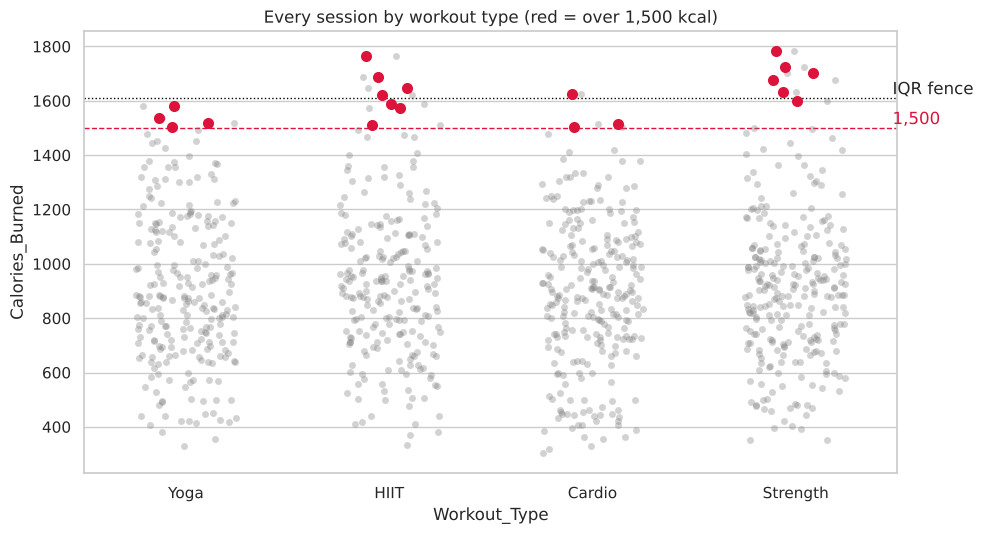

In [7]:
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.stripplot(data=df, x="Workout_Type", y="Calories_Burned", alpha=0.35, jitter=0.25, color="grey", ax=ax)
sns.stripplot(data=high, x="Workout_Type", y="Calories_Burned", color="crimson", size=8, jitter=0.15, ax=ax)
ax.axhline(1500, ls="--", color="crimson", lw=1)
ax.axhline(iqr_fence, ls=":", color="black", lw=1)
ax.text(3.45, 1500, " 1,500", va="bottom", color="crimson")
ax.text(3.45, iqr_fence, " IQR fence", va="bottom")
ax.set_title("Every session by workout type (red = over 1,500 kcal)")
plt.tight_layout(); plt.show()

**Takeaway:**
- Every 1,500+ session is an **experience level 3** member training **about 1.8–2 hours** at a heart rate near 160. Nothing looks like a typo.
- Statistically they're borderline: only a few cross the z-score line.
- The real problem is **plausibility**. 1,500+ calories in a session of HIIT or strength is possible for a fit person. The same number from **yoga** isn't realistic.
- Recommendation: **keep them, flag them, and test whether they change the model** (section 6).

## 3. How Much Do the Main Factors Affect Calories?
Two views side by side:
- **Correlation**: how much each factor moves with calories *on its own*
- **Standardized effect**: each factor's effect *after accounting for all the others* (linear regression on z-scored features)

,Correlation (alone),Standardized effect (together)
Duration,0.91,0.88
Avg_BPM,0.34,0.33
Experience_Level,0.69,-0.04
Frequency,0.58,0.00
Fat_Percentage,-0.60,-0.09
Age,-0.15,-0.15
Weight,0.10,0.08


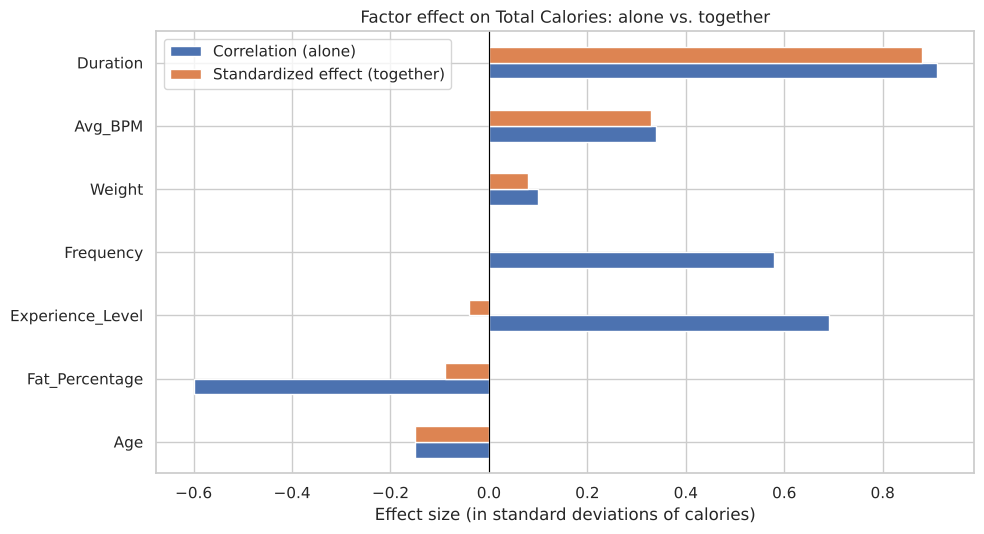

In [8]:
factors = ["Duration", "Avg_BPM", "Experience_Level", "Frequency", "Fat_Percentage", "Age", "Weight"]
X = StandardScaler().fit_transform(df[factors])
lr = LinearRegression().fit(X, df["Calories_Burned"])

effects = pd.DataFrame({
    "Correlation (alone)": df[factors].corrwith(df["Calories_Burned"]),
    "Standardized effect (together)": lr.coef_ / df["Calories_Burned"].std(),
}).round(2)
display(effects)

effects.sort_values("Standardized effect (together)").plot.barh(figsize=(10, 5.5))
plt.axvline(0, color="black", lw=0.8)
plt.title("Factor effect on Total Calories: alone vs. together")
plt.xlabel("Effect size (in standard deviations of calories)")
plt.tight_layout(); plt.show()

**How to read it:** where the two bars disagree, the factor was "riding along" with something else. Experience, frequency and fat % look strong alone, but most of that shrinks once duration and heart rate are in the model. **Duration** and **heart rate** do the real work.

## 4. Experience → Duration → Fat % → Calories?

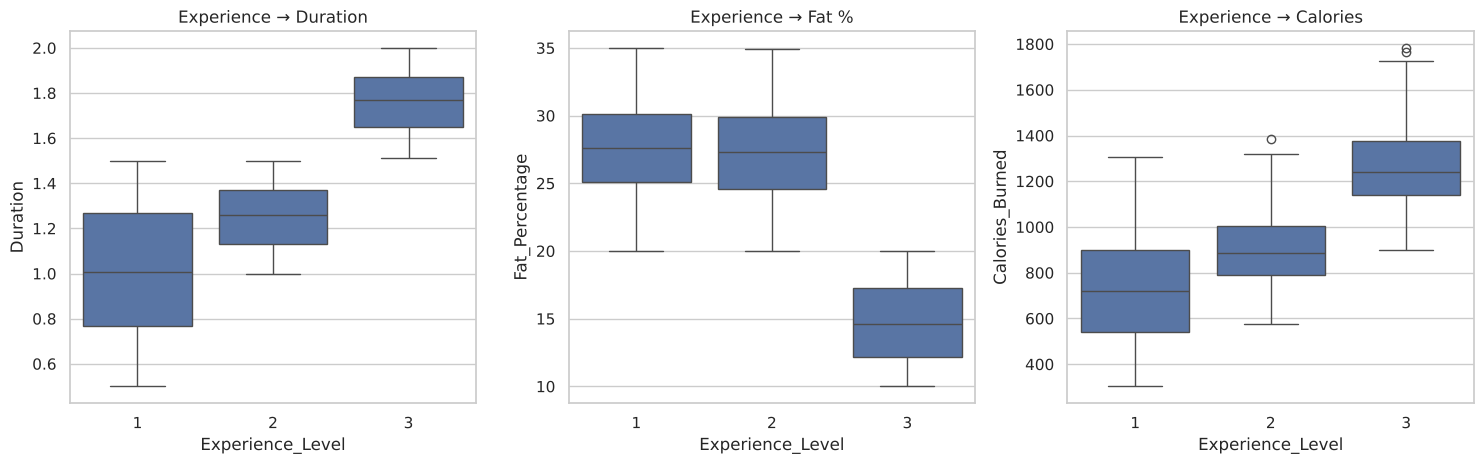

Shortest level-3 session:       1.51 hrs
Longest level-1/2 session:      1.5 hrs


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
sns.boxplot(data=df, x="Experience_Level", y="Duration", ax=axes[0]); axes[0].set_title("Experience → Duration")
sns.boxplot(data=df, x="Experience_Level", y="Fat_Percentage", ax=axes[1]); axes[1].set_title("Experience → Fat %")
sns.boxplot(data=df, x="Experience_Level", y="Calories_Burned", ax=axes[2]); axes[2].set_title("Experience → Calories")
plt.tight_layout(); plt.show()

print("Shortest level-3 session:      ", df.loc[df.Experience_Level == 3, "Duration"].min(), "hrs")
print("Longest level-1/2 session:     ", df.loc[df.Experience_Level < 3, "Duration"].max(), "hrs")

**The cutoff is perfect:** every level-3 member trains more than 1.5 hours and nobody else does. Real gyms don't look like this. It's another sign the data was generated by rules.

Now the key test: **once we know duration, do experience and fat % still add anything?**

In [10]:
def r2(cols):
    X = df[cols]
    return LinearRegression().fit(X, df["Calories_Burned"]).score(X, df["Calories_Burned"])

steps = [
    ["Duration"],
    ["Duration", "Experience_Level"],
    ["Duration", "Experience_Level", "Fat_Percentage"],
    ["Duration", "Avg_BPM"],
]
chain = pd.DataFrame({"Features": [" + ".join(s) for s in steps],
                      "R²": [round(r2(s), 3) for s in steps]})
display(chain)

,Features,R²
0,Duration,0.825
1,Duration + Experience_Level,0.825
2,Duration + Experience_Level + Fat_Percentage,0.833
3,Duration + Avg_BPM,0.930


**Takeaway:** adding experience and fat % on top of duration barely moves R². Adding **heart rate** jumps it a lot. So a better chain is:

> **Experience → longer sessions → more total calories**
> and separately **Experience → lower fat %** (over time)

Fat % and calories are correlated because they **share a cause** (experience), not because body fat changes how many calories one session burns.

## 5. Low / Mid / High: Three Ways to Bin Total Calories

In [11]:
c = df["Calories_Burned"]
labels = ["Low", "Mid", "High"]

df["Bin_EqualFreq"]  = pd.qcut(c, 3, labels=labels)
df["Bin_EqualWidth"] = pd.cut(c, 3, labels=labels)

km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(c.to_frame())
order = np.argsort(km.cluster_centers_.ravel())          # sort clusters low -> high
df["Bin_KMeans"] = pd.Categorical(pd.Series(km.labels_).map({order[i]: labels[i] for i in range(3)}),
                                  categories=labels, ordered=True)

summary = []
for m in ["Bin_EqualFreq", "Bin_EqualWidth", "Bin_KMeans"]:
    g = df.groupby(m, observed=True)["Calories_Burned"].agg(["min", "max", "count"])
    g.insert(0, "Method", m.replace("Bin_", ""))
    summary.append(g.reset_index().rename(columns={m: "Bin"}))
display(pd.concat(summary, ignore_index=True))

,Bin,Method,min,max,count
0,Low,EqualFreq,303.0,784.0,325
1,Mid,EqualFreq,786.0,1006.0,324
2,High,EqualFreq,1009.0,1783.0,324
3,Low,EqualWidth,303.0,796.0,341
4,Mid,EqualWidth,798.0,1289.0,542
5,High,EqualWidth,1290.0,1783.0,90
6,Low,KMeans,303.0,760.0,300
7,Mid,KMeans,762.0,1096.0,446
8,High,KMeans,1100.0,1783.0,227


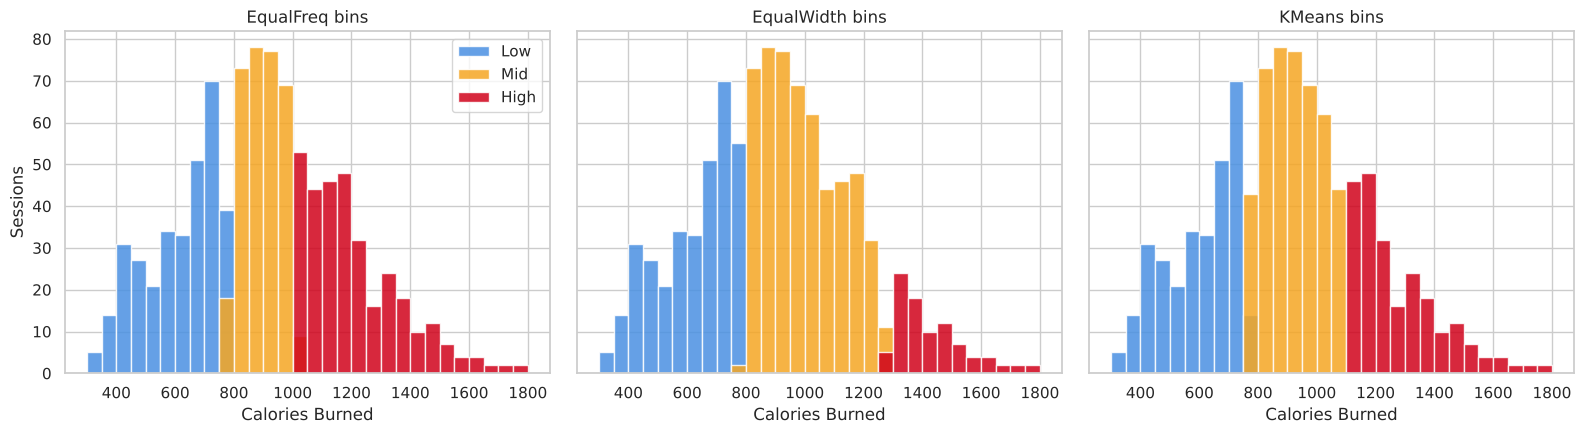

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
colors = {"Low": "#4a90e2", "Mid": "#f5a623", "High": "#d0021b"}
for ax, m in zip(axes, ["Bin_EqualFreq", "Bin_EqualWidth", "Bin_KMeans"]):
    for lab in labels:
        ax.hist(df.loc[df[m] == lab, "Calories_Burned"], bins=np.arange(300, 1850, 50),
                color=colors[lab], label=lab, alpha=0.85)
    ax.set_title(m.replace("Bin_", "") + " bins"); ax.set_xlabel("Calories Burned")
axes[0].set_ylabel("Sessions"); axes[0].legend()
plt.tight_layout(); plt.show()

**Watch out:** do these bins just sort people by experience (and session length)?

In [13]:
display(pd.crosstab(df["Bin_EqualFreq"], df["Experience_Level"], margins=True))

Experience_Level,1,2,3,All
Bin_EqualFreq,,,,
Low,226,99,0,325
Mid,101,207,16,324
High,49,100,175,324
All,376,406,191,973


**Takeaway:** almost every level-3 member lands in **High** and none land in **Low**. A classifier on total-calorie bins would mostly learn *"long session = High."* That's the main weakness of Approach A. Compare with Approach B (per hour).

## 6. Keep or Drop the 1,500+ Sessions?
Cross-validated linear regression error, with and without the flagged sessions.

In [14]:
feats = ["Duration", "Avg_BPM", "Age", "Weight", "Experience_Level", "Fat_Percentage"]
df["Male"] = (df["Gender"] == "Male").astype(int)
feats = feats + ["Male"]

def cv_mae(data):
    return -cross_val_score(LinearRegression(), data[feats], data["Calories_Burned"],
                            cv=5, scoring="neg_mean_absolute_error").mean()

keep = df
drop = df[df["Calories_Burned"] <= 1500]
display(pd.DataFrame({
    "Rows": [len(keep), len(drop)],
    "Avg error (kcal)": [round(cv_mae(keep), 1), round(cv_mae(drop), 1)],
}, index=["Keep all", "Drop >1,500"]))

,Rows,Avg error (kcal)
Keep all,973,30.2
"Drop >1,500",953,28.3


**Takeaway:** if the error barely changes, the 1,500+ sessions aren't distorting the model. Keep them and report this check. That's more defensible than quietly deleting data.